### BONUS QUESTION

Lasso Regression

In [32]:
#data_generator.py
import numpy as np

def fun(x):
    
    #print("compute a simple quadratic function f:R^5 -> R.")

    return 1.3 + 2.*x[0] - 1.1*x[1] + 0.7*x[2]  + 1.2*x[3] + \
            0.4* (x[0]**2) -1.5 *x[1]*x[3] - 0.7 * (x[4]**2) 

def postfix(N,d,sigma):
    """Converts parameters into a handy string, to be appended to file names."""
    return "_N_%d_d_%d" % (N,d) \
         + "_sig_%s" % str(sigma).replace(".","_")      


if __name__ == "__main__":        
    # Set random seed for reproducibility    
    np.random.seed(42)


    # Number of samples
    N = 1000

    # Noise variance 
    sigma = 0.01


    # Feature dimension
    #d = 40 #question 4.3
    d = 40  #question 4.2
  
    print("Generating dataset with N = %d, σ = %f, d = %d..." % (N,sigma,d), end="")

    # Generate random features
    X = np.random.randn(N, d)

    # Generate pure labels
    y = []

    for i in range(N):
        y.append(
                    fun(X[i,:])
                    )
    y = np.array(y)

    # Add noise to labels
    err = np.random.normal(scale = sigma, size = N)
    y = y + err

    print(" done")

    psfx = postfix(N,d,sigma)

    print("Saving X and y... ",end="")
    np.save("X" + psfx,X)
    np.save("y" + psfx,y)
    print(" done")

Generating dataset with N = 1000, σ = 0.010000, d = 40... done
Saving X and y...  done


### BOUNS.1 
_Read through the code in file Lasso.py and explain what it does._

This file reads in random data output of data_generator.py for the given number of samples, variance and dimensions. It performs a 70/30 train/test split on the data. It builds a Lasso regression model with regularization parameter of $\alpha = .1$  It runs 5 fold cross validation on the training data split and prints the Cross-validation RMSE. Finally it fits the linear model over entire training set and prints out the train and test RMSE.

In [33]:

#LassoCV.py

import numpy as np
from sklearn.model_selection import KFold,train_test_split,cross_val_score
from sklearn.linear_model import Lasso
from sklearn.metrics import root_mean_squared_error as rmse
import matplotlib.pyplot as plt
#from data_generator import postfix


def postfix(N,d,sigma):
    """Converts parameters into a handy string, to be appended to file names."""
    return "_N_%d_d_%d" % (N,d) \
         + "_sig_%s" % str(sigma).replace(".","_")    

# Number of samples
N = 1000

# Noise variance 
sigma = 0.01


# Feature dimension
d = 5

psfx = postfix(N,d,sigma) 
      

X = np.load("X"+psfx+".npy")
y = np.load("y"+psfx+".npy")

print("Dataset has n=%d samples, each with d=%d features," % X.shape,"as well as %d labels." % y.shape[0])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42)

print("Randomly split dataset to %d training and %d test samples" % (X_train.shape[0],X_test.shape[0]))


alpha = 0.1

model = Lasso(alpha = alpha)

cv = KFold(
        n_splits=5, 
        random_state=42,
        shuffle=True
        )



scores = cross_val_score(
        model, X_train, y_train, cv=cv,scoring="neg_root_mean_squared_error")


print("Cross-validation RMSE for α=%f : %f ± %f" % (alpha,-np.mean(scores),np.std(scores)) )


print("Fitting linear model over entire training set...",end="")
model.fit(X_train, y_train)
print(" done")


# Compute RMSE
rmse_train = rmse(y_train,model.predict(X_train))
rmse_test = rmse(y_test,model.predict(X_test))

print("Train RMSE = %f, Test RMSE = %f" % (rmse_train,rmse_test))

Dataset has n=1000 samples, each with d=5 features, as well as 1000 labels.
Randomly split dataset to 700 training and 300 test samples
Cross-validation RMSE for α=0.100000 : 1.884717 ± 0.076497
Fitting linear model over entire training set... done
Train RMSE = 1.854995, Test RMSE = 1.789074


### BONUS.2 
_Create a file called LassoSweepAlpha.py that is a modified version of Lasso and implements the following functionality:_
* First, it lifts the dataset before splitting it to a train and test set.
* Then, it performs 5-fold cross validation on the training set for different Lasso reg-ularization parameters α, ranging from 2−¹⁰ to 2¹⁰, and finds the α that minimizes the mean RMSE across folds.
* Finally, the code should re-train a Lasso model over the entire training set under the optimal value of α, and compute the train and test RMSE.

_Run your code on a dataset generated by generate_data.py with N = 1000, d = 40, and σ = 0.01. Plot 
the cross-validation mean RMSE as a function of α (include error bars)._


### BONUS 3. 
_Report also the train and test RMSE for the model with an optimal α. Report also all the parameters (coefficients and intercept) of your finally trained model that have an absolute  value larger than 10−³. Did you do better at learning function fun compared to Q4.8, despite all the nuisance variables? If so, why?_

The Lasso model perfromed better than the linear regression of question 4.8, lasso regression perfroms better for sparse $fun$, driving unimportant coefficients to zero.


Lifted dataset has n=1000 samples, each with d'=860 features.
Randomly split dataset to 700 training and 300 test samples
alpha = 2^-10 : CV RMSE = 0.010260 ± 0.000621
alpha = 2^ -9 : CV RMSE = 0.011133 ± 0.000719
alpha = 2^ -8 : CV RMSE = 0.014380 ± 0.000797
alpha = 2^ -7 : CV RMSE = 0.023202 ± 0.000771
alpha = 2^ -6 : CV RMSE = 0.043161 ± 0.001049
alpha = 2^ -5 : CV RMSE = 0.084599 ± 0.002430
alpha = 2^ -4 : CV RMSE = 0.168300 ± 0.005569
alpha = 2^ -3 : CV RMSE = 0.336120 ± 0.011971
alpha = 2^ -2 : CV RMSE = 0.671973 ± 0.024821
alpha = 2^ -1 : CV RMSE = 1.343786 ± 0.050540
alpha = 2^  0 : CV RMSE = 2.432294 ± 0.086523
alpha = 2^  1 : CV RMSE = 3.053323 ± 0.079406
alpha = 2^  2 : CV RMSE = 3.129700 ± 0.064486
alpha = 2^  3 : CV RMSE = 3.129700 ± 0.064486
alpha = 2^  4 : CV RMSE = 3.129700 ± 0.064486
alpha = 2^  5 : CV RMSE = 3.129700 ± 0.064486
alpha = 2^  6 : CV RMSE = 3.129700 ± 0.064486
alpha = 2^  7 : CV RMSE = 3.129700 ± 0.064486
alpha = 2^  8 : CV RMSE = 3.129700 ± 0.064486
alph

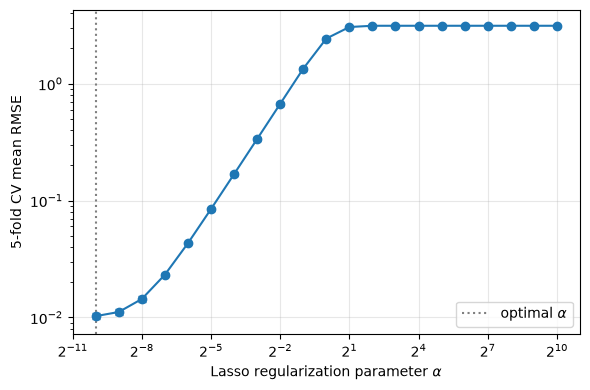

Optimal alpha = 0.000977 (2^-10)
Train RMSE = 0.009984, Test RMSE = 0.010189

Intercept: learned 1.29890 (true 1.3)
Coefficients with |value| > 1e-3:
  term        learned       true
  x0          1.99912       2.00
  x1         -1.09953      -1.10
  x2          0.69866       0.70
  x3          1.19924       1.20
  x0*x0       0.39983       0.40
  x3*x1      -1.49936      -1.50
  x4*x4      -0.69895      -0.70

Nonzero coefficients (exactly): 14 of 860
Coefficients with |value| > 1e-3: 7


In [34]:
#LassoSWEEP_ALPHA.py

import numpy as np
from sklearn.model_selection import KFold,train_test_split,cross_val_score
from sklearn.linear_model import Lasso
from sklearn.metrics import root_mean_squared_error as rmse
import matplotlib.pyplot as plt
#from data_generator import postfix


def postfix(N,d,sigma):
    """Converts parameters into a handy string, to be appended to file names."""
    return "_N_%d_d_%d" % (N,d) \
         + "_sig_%s" % str(sigma).replace(".","_")    

# --- AI-generated (Claude, Anthropic) ---
def lift(x):
    x = np.asarray(x)
    d = x.shape[-1]
    quad = [x[..., i] * x[..., j] for i in range(d) for j in range(i + 1)]
    return np.concatenate([x, np.stack(quad, axis=-1)], axis=-1)

def liftDataset(X):
    return np.array([lift(x) for x in X])
# --- end AI-generated ---

# Number of samples
N = 1000

# Noise variance 
sigma = 0.01


# Feature dimension
d = 40

psfx = postfix(N,d,sigma) 
      

X = np.load("X"+psfx+".npy")
y = np.load("y"+psfx+".npy")

# --- AI-generated (Claude, Anthropic) ---
X = liftDataset(X)   # lift before splitting
print("Lifted dataset has n=%d samples, each with d'=%d features." % X.shape)
# --- end AI-generated ---


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42)

print("Randomly split dataset to %d training and %d test samples" % (X_train.shape[0],X_test.shape[0]))


alphas = 2.0 ** np.arange(-10, 11)     # 2^-10, ..., 2^10
cv_mean, cv_std = [], []

for alpha in alphas:
    model = Lasso(alpha=alpha, max_iter=100000)
    scores = cross_val_score(
        model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    cv_mean.append(-np.mean(scores))
    cv_std.append(np.std(scores))
    print("alpha = 2^%3d : CV RMSE = %f ± %f" % (round(np.log2(alpha)), cv_mean[-1], cv_std[-1]))

best_alpha = alphas[int(np.argmin(cv_mean))]
print("Optimal alpha = %f" % best_alpha)
# --- end AI-generated ---

cv = KFold(
        n_splits=5, 
        random_state=42,
        shuffle=True
        )
# --- AI-generated (Claude, Anthropic) ---
plt.figure(figsize=(6,4))
plt.errorbar(alphas, cv_mean, yerr=cv_std, fmt="o-", capsize=3)
plt.axvline(best_alpha, ls=":", c="gray", label="optimal $\\alpha$")
plt.xscale("log", base=2)
plt.yscale("log")
plt.xlabel("Lasso regularization parameter $\\alpha$")
plt.ylabel("5-fold CV mean RMSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("lasso_cv_vs_alpha.png", dpi=150)
plt.show()


model = Lasso(alpha=best_alpha, max_iter=100000)
# --- End AI-generated (Claude, Anthropic) ---

model.fit(X_train, y_train)

# --- AI-generated (Claude, Anthropic) ---
# Train/test RMSE at the optimal alpha
rmse_train = rmse(y_train, model.predict(X_train))
rmse_test = rmse(y_test, model.predict(X_test))
print("Optimal alpha = %f (2^%d)" % (best_alpha, round(np.log2(best_alpha))))
print("Train RMSE = %f, Test RMSE = %f" % (rmse_train, rmse_test))

# Names of the lifted features, in the same order as lift()
names = ["x%d" % i for i in range(d)] + \
        ["x%d*x%d" % (i, j) for i in range(d) for j in range(i + 1)]

# True coefficients of fun (feature x3*x1 is the same as x1*x3)
true = {"x0": 2.0, "x1": -1.1, "x2": 0.7, "x3": 1.2,
        "x0*x0": 0.4, "x3*x1": -1.5, "x4*x4": -0.7}

# Parameters with |value| > 1e-3
print("\nIntercept: learned %.5f (true 1.3)" % model.intercept_)
print("Coefficients with |value| > 1e-3:")
print("  %-8s %10s %10s" % ("term", "learned", "true"))
for n, c in zip(names, model.coef_):
    if abs(c) > 1e-3:
        print("  %-8s %10.5f %10.2f" % (n, c, true.get(n, 0.0)))

print("\nNonzero coefficients (exactly): %d of %d" % (np.sum(model.coef_ != 0), model.coef_.size))
print("Coefficients with |value| > 1e-3: %d" % np.sum(np.abs(model.coef_) > 1e-3))
# --- end AI-generated ---